# Parte 1 — Dataset y preprocesamiento para reconocimiento facial

Notebook de documentación, tratamiento de datos y preparación del dataset. Sigue la misma estructura que el laboratorio de la Clase 2 (setup → datos → inspección → preprocesamiento → splits), aplicada a **rostros**.

## Equipo
- Alumno 1 : Uriel Duvia
- Alumno 2 : Laureano Diez

## Índice

**Setup**

1. [Ideas clave](#key-ideas)
2. [Instalar paquetes](#install)
3. [Obtener el repositorio](#clone-repo)
4. [Descargar los modelos de InsightFace](#models)
5. [Imports y configuración](#imports)

**Datos**

6. [Elección y descarga del dataset (Pins Face Recognition)](#dataset)
7. [Listas de archivos e identidades](#file-lists)
8. [Distribución de imágenes por identidad](#class-distribution)
9. [Resoluciones, brillo y formato](#eda-quality-basic)
10. [Muestra visual](#visualize)

**Preprocesamiento**

11. [Detección, alineación y reglas de calidad](#quality)
12. [Antes / después de la alineación](#before-after)
13. [Embeddings y clustering exploratorio](#clustering)
14. [Duplicados y outliers de etiqueta](#outliers)
15. [Data augmentation](#augmentation)
16. [Splits closed-set y open-set](#splits)
17. [Verificación de fuga de datos](#leakage)
18. [Tabla resumen](#summary)

**Cierre**

19. [Ética, privacidad y licencias](#ethics)
20. [Conclusiones](#takeaways)

<a name='key-ideas'></a>
## Ideas clave

- **Un solo pipeline.** Detección, alineación y normalización viven en `src/lib/face_pipeline.py` y se importan tanto aquí como en el backend (`face_service.py`). Es la causa número uno de "anda en la notebook pero no en la app".
- **Leer el preprocesamiento del modelo, no hardcodearlo.** Igual que en la Clase 2 con `timm`: el tamaño de entrada se lee del ONNX (`fp.model_input_size`) y la normalización de ArcFace es `(x - 127.5) / 127.5` en RGB.
- **Reglas de filtrado explícitas, reproducibles y con conteo.** Cada regla informa cuántas imágenes descarta y muestra ejemplos.
- **Dos escenarios de split.** *Closed-set* (mismas identidades en train y test) y *open-set* (identidades de test nunca vistas), que es el caso real de la app porque se registran personas nuevas.
- **Semillas fijas y splits guardados** en CSV para que `2-train.ipynb` los reutilice sin recalcular nada.

<a name='install'></a>
## Instalar paquetes

In [1]:
import sys

if "google.colab" in sys.modules:
    # Colab: instalamos lo que la VM no trae.
    %pip install -q insightface==0.7.3 onnxruntime umap-learn albumentations imagehash kagglehub
else:
    # Local: NO usar `!pip` (puede apuntar a otro Python y ensuciar el entorno global).
    # Instalar desde la terminal, con el .venv activo:
    #   uv pip install -r requirements.txt   (en Windows: sin uvloop)
    #   uv pip install imagehash kagglehub
    print("Entorno local: las dependencias se instalan desde la terminal (ver comentarios).")

Entorno local: las dependencias se instalan desde la terminal (ver comentarios).


<a name='clone-repo'></a>
## Obtener el repositorio

In [2]:
import os

REPO_URL = "https://github.com/laureanodiez/tuia-face-recognition-app.git"
REPO_DIR = "tuia-face-recognition-app"

if not os.path.isfile("src/lib/face_pipeline.py"):
    if not os.path.isdir(REPO_DIR) and os.path.basename(os.getcwd()) != REPO_DIR:
        !git clone -q $REPO_URL
    if os.path.basename(os.getcwd()) != REPO_DIR:
        %cd $REPO_DIR

print("Working directory:", os.getcwd())
print("face_pipeline presente:", os.path.isfile("src/lib/face_pipeline.py"))

Working directory: g:\Academicos\FCEIA\QUINTO CUATRIMESTRE\CV\tuia-face-recognition-app
face_pipeline presente: True


<a name='models'></a>
## Descargar los modelos de InsightFace

Usamos dos modelos del paquete `buffalo_l`:

| Archivo | Rol | Entrada |
| --- | --- | --- |
| `det_10g.onnx` | Detector SCRFD (caja + 5 landmarks) | imagen BGR, redimensionada a `DET_INPUT_SIZE` |
| `w600k_r50.onnx` | Reconocedor ArcFace ResNet-50 (embedding de 512 dims) | 3 × 112 × 112, RGB, `(x - 127.5) / 127.5` |

> **Licencia:** los modelos preentrenados de InsightFace son para uso **no comercial / investigación**. Los pesos no se versionan (`*.onnx` está en `.gitignore`).

In [3]:
import urllib.request
import zipfile

os.makedirs("models", exist_ok=True)
NEEDED = ["det_10g.onnx", "w600k_r50.onnx"]

if not all(os.path.isfile(f"models/{n}") for n in NEEDED):
    url = "https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip"
    urllib.request.urlretrieve(url, "models/buffalo_l.zip")
    with zipfile.ZipFile("models/buffalo_l.zip") as z:
        for n in NEEDED:
            z.extract(n, "models")
    os.remove("models/buffalo_l.zip")

print({n: os.path.isfile(f"models/{n}") for n in NEEDED})

{'det_10g.onnx': True, 'w600k_r50.onnx': True}


<a name='imports'></a>
## Imports y configuración

Todos los umbrales del preprocesamiento están **juntos en una celda** para que sean fáciles de justificar y de cambiar. Los umbrales se validaron mirando los ejemplos descartados (sección 11).

In [ ]:
import glob
import json
import random
import sys
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

sys.path.insert(0, "src")
from lib import face_pipeline as fp  # mismo módulo que usa el backend

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Dataset ---
MAX_IMGS_PER_ID_RAW = 100   # tope de imágenes por identidad al copiar el dataset (acelera la detección); None = todas
MIN_IMGS_AFTER_FILTER = 10  # identidades que quedan con menos imágenes tras la limpieza se descartan

# --- Pipeline facial ---
FACE_SIZE = 112
DET_SCORE_THRESHOLD = 0.5
DET_INPUT_SIZE = 640
# Las fotos de Pins son recortes ajustados (la cara llena todo el cuadro) y SCRFD no los detecta sin contexto.
# Por eso se agrega un borde negro de PAD_FRAC * (alto/ancho) a cada lado ANTES de detectar.
# En el backend, el equivalente es DET_PAD_FRAC del .env (reintento cuando no se detecta nada).
PAD_FRAC = 0.5

# --- Reglas de calidad ---
MIN_FACE_PX = 40            # lado mínimo de la caja del rostro
MAX_SECOND_FACE_RATIO = 0.5 # si el 2º rostro mide > 50% del área del 1º, la imagen es ambigua
BLUR_THRESHOLD = 40.0       # varianza del Laplaciano del rostro alineado (más bajo = más borroso)
BRIGHT_MIN, BRIGHT_MAX = 35, 220  # brillo medio (0-255) del rostro alineado
PHASH_DIST = 4              # distancia de Hamming máxima para considerar duplicado perceptual
NEAR_DUP_SIM = 0.95         # similitud coseno de embeddings para casi-duplicados
OUTLIER_SIM = 0.20          # similitud mínima al centroide de la propia identidad

# --- Splits ---
FRAC_KNOWN_IDS = 0.70       # identidades "conocidas" (closed-set); el resto es open-set
CLOSED_TRAIN, CLOSED_VAL = 0.70, 0.15  # el resto es test closed-set

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
ALIGNED_DIR = DATA_DIR / "aligned"
SPLITS_DIR = DATA_DIR / "splits"
for d in (RAW_DIR, ALIGNED_DIR, SPLITS_DIR):
    d.mkdir(parents=True, exist_ok=True)

C:\Users\PC\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a name='dataset'></a>
## Elección y descarga del dataset (Pins Face Recognition)

**Dataset elegido: Pins Face Recognition** (Kaggle, `hereisburak/pins-face-recognition`), descargado con `kagglehub`.

| Aspecto | Detalle |
| --- | --- |
| Tamaño | 105 identidades y 10.479 imágenes|
| Contenido | fotos de celebridades, 10.088 imágenes finales. |
| Resolución | variable (a diferencia de LFW no hay un tamaño fijo): se mide en la sección 9 |
| Licencia | CC0: Public Domain |

**Por qué lo elegimos:** tiene muchas imágenes por persona (100 por identidad por el tope que se aplicó para acelerar la detección), lo que lo hace más adecuado que LFW para entrenar la CNN custom (clasificación + embedding).

**Limitaciones:**
- **Sesgo de celebridades:** son personas públicas, con fotos muy cuidadas o retocadas; no representan cámaras de acceso.
- **Calidad de las etiquetas:** al provenir de una recolección web puede haber imágenes mal etiquetadas y duplicados. Para eso están el hash perceptual y el análisis de outliers de las secciones 11 y 14.
- **Resolución y encuadre variables**, marcas de agua, filtros y fotos grupales.
- **Recortes ajustados de rostro:** la cara llena todo el cuadro, y el detector necesita un margen para encontrarla (ver sección 11).
- **Sesgo demográfico:** revisar quiénes son las identidades de la muestra visual antes de afirmar nada.

Además, artilujios y distintas características eventuales pueden modificar las caras, como maquillaje, anteojos y fotos en distintas edades de un mismo famoso.

In [ ]:
import shutil

import kagglehub

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def find_identity_root(root):
    root = Path(root)
    best, best_n = None, 0
    for d in [root, *[p for p in root.rglob("*") if p.is_dir()]]:
        n = sum(1 for s in d.iterdir()
                if s.is_dir() and any(f.suffix.lower() in IMG_EXT for f in s.iterdir() if f.is_file()))
        if n > best_n:
            best, best_n = d, n
    return best


if not any(RAW_DIR.iterdir()):
    kaggle_path = kagglehub.dataset_download("hereisburak/pins-face-recognition")
    print("Path to dataset files:", kaggle_path)

    src_root = find_identity_root(kaggle_path)
    print("Carpeta de identidades:", src_root)

    rng_raw = np.random.RandomState(SEED)
    for ident_dir in sorted(p for p in src_root.iterdir() if p.is_dir()):
        name = ident_dir.name.removeprefix("pins_").strip().replace(" ", "_")   # "pins_Adriana Lima" -> "Adriana_Lima"
        files = sorted(f for f in ident_dir.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT)
        if not files:
            continue
        if MAX_IMGS_PER_ID_RAW is not None and len(files) > MAX_IMGS_PER_ID_RAW:
            files = sorted(rng_raw.choice(files, size=MAX_IMGS_PER_ID_RAW, replace=False))
        out_dir = RAW_DIR / name
        out_dir.mkdir(exist_ok=True)
        for i, f in enumerate(files):
            dest = out_dir / f"{i:05d}.jpg"
            if f.suffix.lower() in (".jpg", ".jpeg"):
                shutil.copyfile(f, dest)          # se copia tal cual (si está corrupta, el EDA la reporta)
            else:
                img = cv2.imread(str(f))
                if img is not None:
                    cv2.imwrite(str(dest), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
else:
    print("data/raw ya existe: se reutiliza.")

100%|██████████| 372M/372M [01:08<00:00, 5.70MB/s] 

Extracting files...


Path to dataset files: C:\Users\PC\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1
Carpeta de identidades: C:\Users\PC\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset


<a name='file-lists'></a>
## Listas de archivos e identidades

Igual que en la Clase 2: juntamos las rutas en una tabla y asignamos una etiqueta entera `0 … n-1` por identidad.

In [7]:
rows = []
for ident_dir in sorted(p for p in RAW_DIR.iterdir() if p.is_dir()):
    for p in sorted(ident_dir.glob("*.jpg")):
        rows.append({"path": str(p), "identity": ident_dir.name})

df = pd.DataFrame(rows)
identities = sorted(df.identity.unique())
label_of = {name: i for i, name in enumerate(identities)}
df["label"] = df.identity.map(label_of)

print(f"Imágenes: {len(df)} | Identidades: {len(identities)}")
df.head()

Imágenes: 10479 | Identidades: 105


,path,identity,label
0,data\raw\Adriana_Lima\00000.jpg,Adriana_Lima,0
1,data\raw\Adriana_Lima\00001.jpg,Adriana_Lima,0
2,data\raw\Adriana_Lima\00002.jpg,Adriana_Lima,0
3,data\raw\Adriana_Lima\00003.jpg,Adriana_Lima,0
4,data\raw\Adriana_Lima\00004.jpg,Adriana_Lima,0


<a name='class-distribution'></a>
## Distribución de imágenes por identidad

El cociente entre la identidad más grande y la más chica dice cuánto pesa el desbalance. Va a condicionar la CNN custom (class weights, sampler o augmentation dirigida) y la elección de la métrica.

count    105.0
mean      99.8
std        1.5
min       86.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: count, dtype: float64


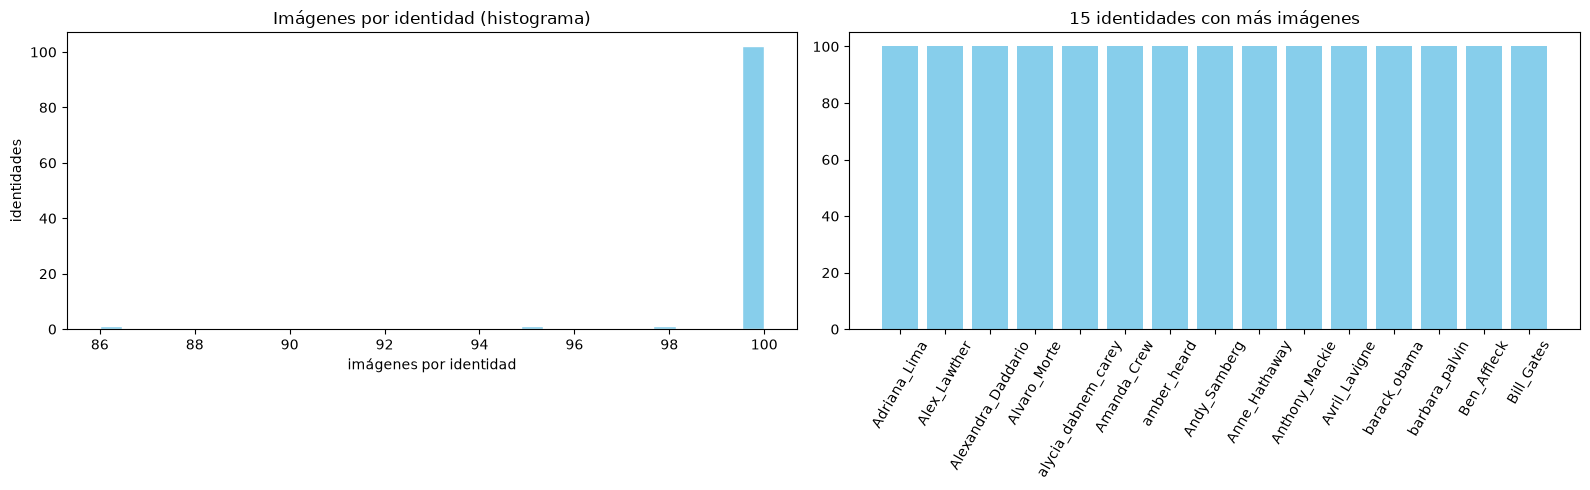

Mediana: 100 | media: 99.8 | mín: 86 | máx: 100 | máx/mín: 1.2x


In [8]:
counts = df.identity.value_counts()
print(counts.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(counts.values, bins=30, color="skyblue", edgecolor="white")
axes[0].set_title("Imágenes por identidad (histograma)")
axes[0].set_xlabel("imágenes por identidad"); axes[0].set_ylabel("identidades")
top = counts.head(15)
axes[1].bar(top.index, top.values, color="skyblue")
axes[1].set_title("15 identidades con más imágenes")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

print(f"Mediana: {counts.median():.0f} | media: {counts.mean():.1f} | "
      f"mín: {counts.min()} | máx: {counts.max()} | máx/mín: {counts.max() / counts.min():.1f}x")

count    105.0
mean     167.0
std       34.1
min       86.0
25%      141.0
50%      169.0
75%      192.0
max      237.0
dtype: float64


<Axes: >

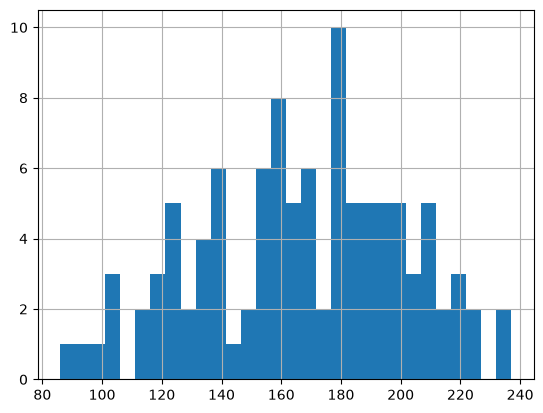

In [27]:
src_root = find_identity_root(kagglehub.dataset_download("hereisburak/pins-face-recognition"))
orig = pd.Series({p.name.removeprefix("pins_").strip().replace(" ", "_"):
                  sum(f.suffix.lower() in IMG_EXT for f in p.iterdir() if f.is_file())
                  for p in src_root.iterdir() if p.is_dir()})
print(orig.describe().round(1)); orig.hist(bins=30)

<a name='eda-quality-basic'></a>
## Resoluciones, brillo y formato

Antes de usar el detector, miramos las propiedades crudas: tamaño, relación de aspecto, canales, archivos que no abren y distribución de brillo. El rostro dentro de la imagen se mide recién en la sección 11.

100%|██████████| 10479/10479 [00:05<00:00, 1917.47it/s]


Archivos que no abren: 0
Tamaños distintos: 501 | canales: [3]


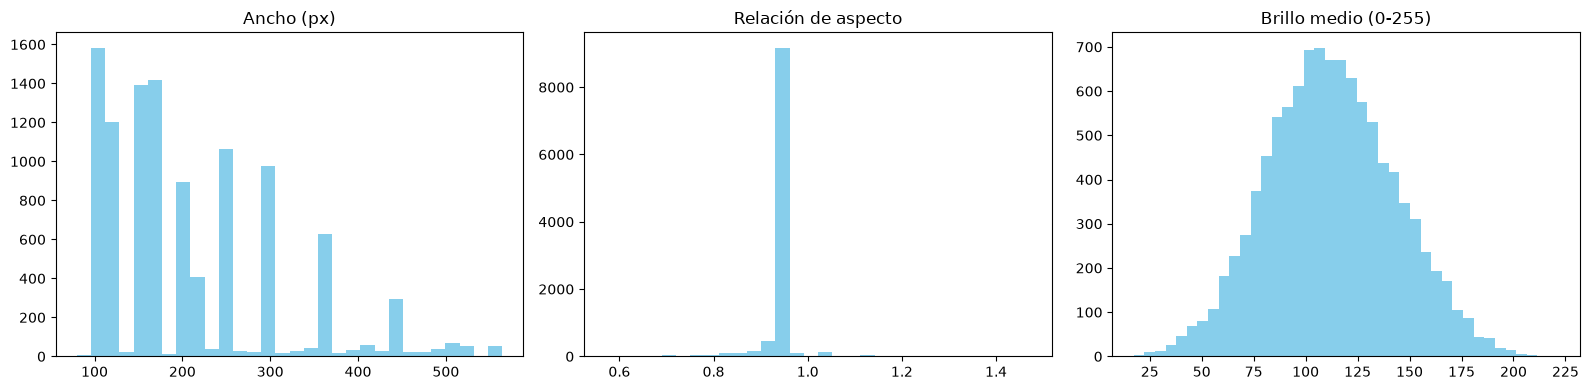

In [9]:
meta = []
for p in tqdm(df.path):
    img = cv2.imread(p)
    if img is None:
        meta.append({"ok": False, "w": np.nan, "h": np.nan, "channels": np.nan, "brightness": np.nan})
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    meta.append({"ok": True, "w": img.shape[1], "h": img.shape[0], "channels": img.shape[2],
                 "brightness": float(gray.mean())})
raw_meta = pd.DataFrame(meta)

print("Archivos que no abren:", int((~raw_meta.ok).sum()))
print("Tamaños distintos:", raw_meta[["w", "h"]].drop_duplicates().shape[0],
      "| canales:", raw_meta.channels.dropna().unique())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(raw_meta.w.dropna(), bins=30, color="skyblue"); axes[0].set_title("Ancho (px)")
axes[1].hist((raw_meta.w / raw_meta.h).dropna(), bins=30, color="skyblue"); axes[1].set_title("Relación de aspecto")
axes[2].hist(raw_meta.brightness.dropna(), bins=40, color="skyblue"); axes[2].set_title("Brillo medio (0-255)")
plt.tight_layout(); plt.show()

<a name='visualize'></a>
## Muestra visual

Cuatro imágenes de cinco identidades al azar, para mirar con ojos humanos las variaciones de pose, iluminación y oclusión antes de confiar en cualquier número.

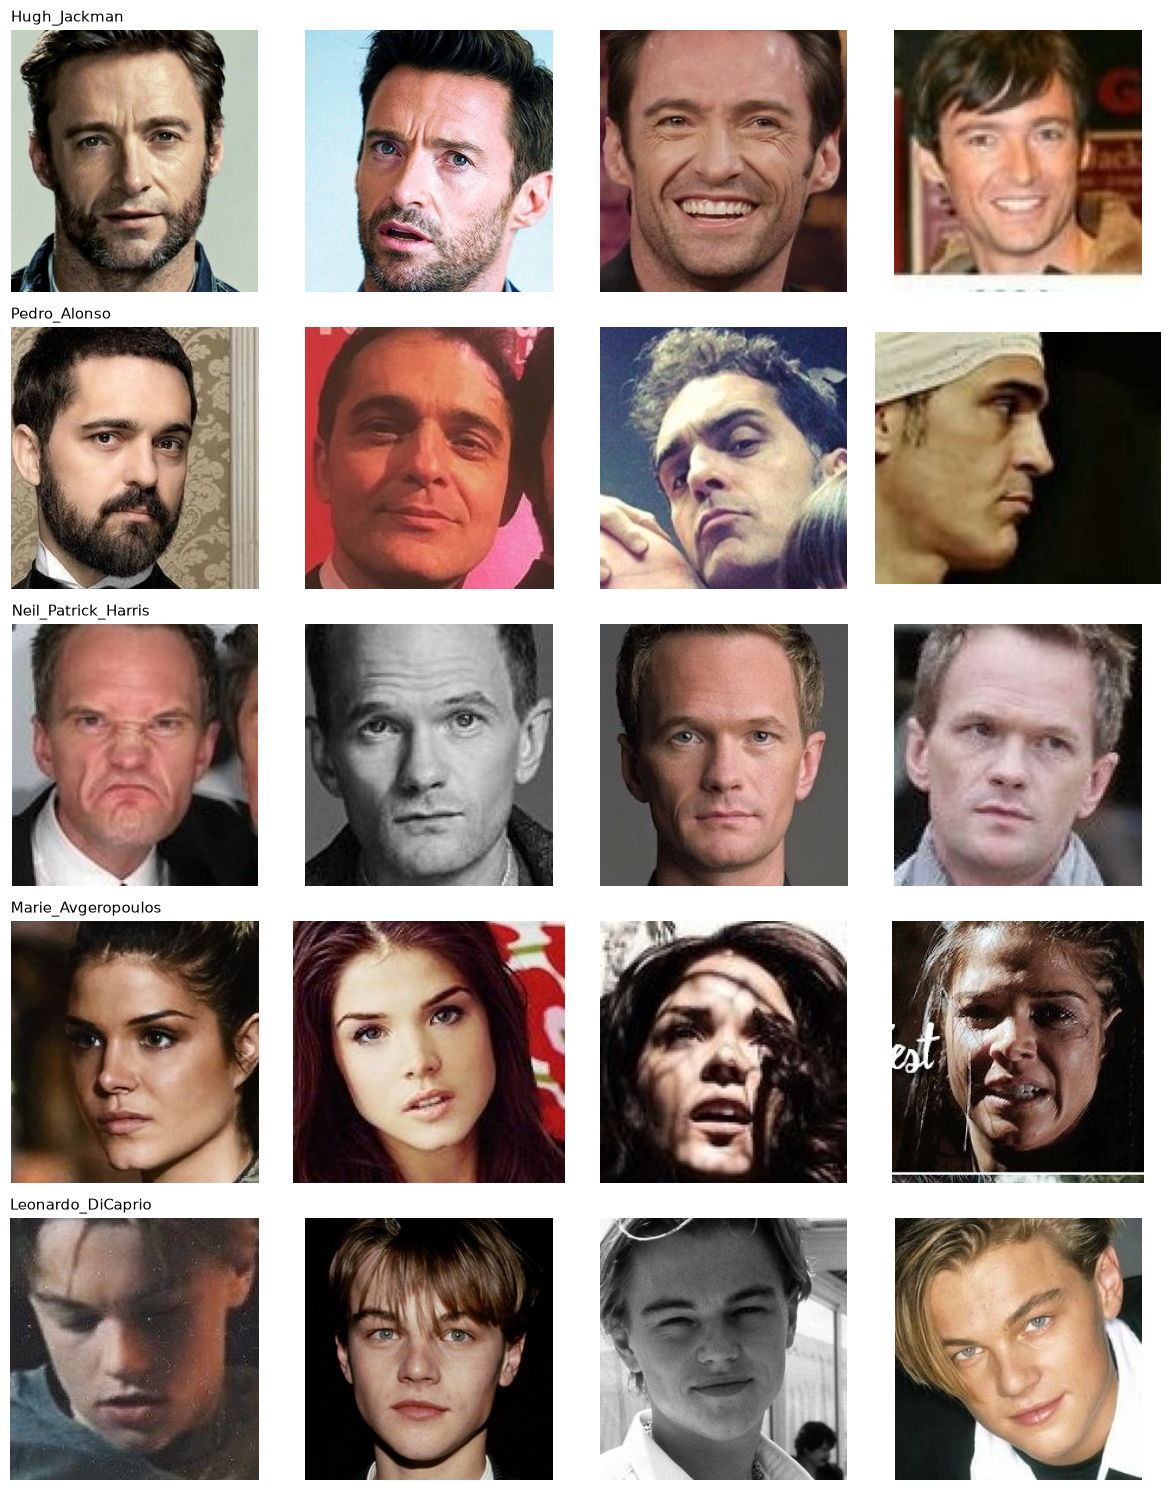

In [10]:
rng = np.random.RandomState(SEED)
sample_ids = rng.choice(identities, size=5, replace=False)

fig, axes = plt.subplots(5, 4, figsize=(12, 15))
for r, name in enumerate(sample_ids):
    paths = df[df.identity == name].path.values
    for c, p in enumerate(rng.choice(paths, size=4, replace=False)):
        ax = axes[r, c]
        ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        ax.axis("off")
        if c == 0:
            ax.set_title(name, fontsize=11, loc="left")
plt.tight_layout(); plt.show()

<a name='quality'></a>
## Detección, alineación y reglas de calidad

**Detector: SCRFD (`det_10g`).** Elegido porque entrega caja **y** los 5 landmarks en una sola pasada, es rápido en CPU y es el mismo que usa el backend, de modo que lo que se filtra aquí es lo que la app podría detectar en producción.

> **Recortes ajustados y margen de detección.** Las fotos de Pins son recortes donde la cara llena todo el cuadro. SCRFD se entrenó con fotos que tienen contexto alrededor de la cara y, sin margen, no detectó ningún rostro en el 91 % de las imágenes (primera ejecución). Por eso la detección agrega un borde negro de `PAD_FRAC` a cada lado y luego corrige las coordenadas a las de la imagen original. La alineación y el embedding no cambian.

Por cada imagen:
1. detectamos rostros y elegimos el **rostro principal** (el de mayor área);
2. lo alineamos a 112 × 112 con los 5 landmarks (`norm_crop`, plantilla ArcFace);
3. medimos nitidez (varianza del Laplaciano) y brillo **sobre el rostro alineado**, que es lo que realmente ve el modelo.

Las reglas se aplican **en orden** y cada imagen se cuenta en la primera que falla; además se informa cuántas fallan cada regla de forma independiente.

In [11]:
detector = fp.load_scrfd("models/det_10g.onnx", DET_SCORE_THRESHOLD, DET_INPUT_SIZE)


def box_area(d):
    return max(0.0, d.box[2] - d.box[0]) * max(0.0, d.box[3] - d.box[1])


def analyze(path, identity):
    img = cv2.imread(path)
    if img is None:
        return {"corrupt": True, "n_faces": 0}
    h, w = img.shape[:2]
    # pad_frac: borde para detectar rostros que llenan todo el cuadro (coordenadas devueltas = las de la imagen original)
    dets = sorted(fp.detect_raw(detector, img, pad_frac=PAD_FRAC), key=box_area, reverse=True)
    out = {"corrupt": False, "n_faces": len(dets)}
    if not dets:
        return out
    main = dets[0]
    x1, y1, x2, y2 = (int(round(v)) for v in main.box)
    face_px = int(min(x2 - x1, y2 - y1))                          # tamaño real del rostro (puede salirse de la foto)
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(w, x2), min(h, y2)  # caja recortada a la imagen, para dibujar
    aligned = fp.align_with_landmarks(img, main.kps, FACE_SIZE)
    gray = cv2.cvtColor(aligned, cv2.COLOR_BGR2GRAY)

    aligned_path = ALIGNED_DIR / identity / (Path(path).stem + ".jpg")
    aligned_path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(aligned_path), aligned, [cv2.IMWRITE_JPEG_QUALITY, 95])

    out.update({
        "box": [x1, y1, x2, y2],
        "kps": main.kps.round(1).tolist(),
        "det_score": round(main.score, 4),
        "face_px": face_px,
        "second_ratio": (box_area(dets[1]) / box_area(main)) if len(dets) > 1 else 0.0,
        "blur": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "brightness": float(gray.mean()),
        "aligned_path": str(aligned_path),
    })
    return out

### Prueba rápida antes de procesar todo

El análisis completo tarda más de una hora. Antes de lanzarlo probamos con **200 imágenes al azar** y miramos qué porcentaje de rostros detecta con `PAD_FRAC`. Si la tasa es baja (< 95 %), conviene ajustar `PAD_FRAC` antes de seguir. En la primera ejecución, sin borde, la detección fallaba en el 91 % de las imágenes.

In [ ]:
sample_df = df.sample(200, random_state=SEED)
sample_res = [analyze(p, i) for p, i in tqdm(zip(sample_df.path, sample_df.identity), total=len(sample_df))]
rate = float(np.mean([r["n_faces"] > 0 for r in sample_res]))
print(f"Rostros detectados con PAD_FRAC={PAD_FRAC}: {rate:.1%} de {len(sample_res)} imágenes")
if rate < 0.95:
    print("Tasa baja: probá otro PAD_FRAC (0.25 a 1.0) o revisá las imágenes sin detección antes de seguir.")

  0%|          | 0/200 [00:00<?, ?it/s]C:\Users\PC\AppData\Roaming\Python\Python312\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)
100%|██████████| 200/200 [00:17<00:00, 11.37it/s]

Rostros detectados con PAD_FRAC=0.5: 100.0% de 200 imágenes


### Análisis completo

In [13]:
results = [analyze(p, i) for p, i in tqdm(zip(df.path, df.identity), total=len(df))]
df = pd.concat([df.reset_index(drop=True), pd.DataFrame(results)], axis=1)
df["n_faces"] = df.n_faces.fillna(0).astype(int)
df.head()

100%|██████████| 10479/10479 [13:54<00:00, 12.55it/s]


,path,identity,label,corrupt,n_faces,box,kps,det_score,face_px,second_ratio,blur,brightness,aligned_path
0,data\raw\Adriana_Lima\00000.jpg,Adriana_Lima,0,False,1,"[24, 4, 115, 139]","[[46.200001, 59.700001], [92.800003, 57.799999...",0.8748,91,0.0,472.560012,100.548390,data\aligned\Adriana_Lima\00000.jpg
1,data\raw\Adriana_Lima\00001.jpg,Adriana_Lima,0,False,1,"[31, 5, 145, 177]","[[57.799999, 74.400002], [115.699997, 76.80000...",0.8845,114,0.0,848.635297,111.358418,data\aligned\Adriana_Lima\00001.jpg
2,data\raw\Adriana_Lima\00002.jpg,Adriana_Lima,0,False,1,"[13, 12, 110, 138]","[[42.400002, 66.900002], [86.300003, 63.700001...",0.8713,97,0.0,843.994144,83.005182,data\aligned\Adriana_Lima\00002.jpg
3,data\raw\Adriana_Lima\00003.jpg,Adriana_Lima,0,False,1,"[23, 15, 85, 95]","[[46.799999, 50.299999], [74.699997, 49.599998...",0.7239,62,0.0,449.243511,92.753508,data\aligned\Adriana_Lima\00003.jpg
4,data\raw\Adriana_Lima\00004.jpg,Adriana_Lima,0,False,1,"[43, 2, 137, 133]","[[59.0, 48.700001], [99.699997, 66.099998], [6...",0.8468,94,0.0,771.872149,86.657286,data\aligned\Adriana_Lima\00004.jpg


In [14]:
# Cada regla como una condición booleana independiente (True = la imagen FALLA la regla).
rules = {
    "1. archivo corrupto":      df.corrupt.fillna(False),
    "2. sin rostro":            (~df.corrupt.fillna(False)) & (df.n_faces == 0),
    "3. rostro ambiguo (2+)":   df.second_ratio.fillna(0) > MAX_SECOND_FACE_RATIO,
    "4. rostro muy chico":      df.face_px.fillna(0).lt(MIN_FACE_PX) & (df.n_faces > 0),
    "5. borrosa":               df.blur.lt(BLUR_THRESHOLD),
    "6. exposición extrema":    df.brightness.lt(BRIGHT_MIN) | df.brightness.gt(BRIGHT_MAX),
}

# Primera regla que falla (descarte secuencial) y conteo independiente.
df["discard_reason"] = ""
for name, failed in rules.items():
    df.loc[(df.discard_reason == "") & failed, "discard_reason"] = name

summary = pd.DataFrame({
    "falla la regla (independiente)": {k: int(v.sum()) for k, v in rules.items()},
    "descartadas (secuencial)": df.discard_reason.value_counts().reindex(list(rules)).fillna(0).astype(int),
})
print(f"Total: {len(df)} | conservadas tras reglas 1-6: {(df.discard_reason == '').sum()}")
summary

Total: 10479 | conservadas tras reglas 1-6: 10421


,falla la regla (independiente),descartadas (secuencial)
1. archivo corrupto,0,0
2. sin rostro,0,0
3. rostro ambiguo (2+),0,0
4. rostro muy chico,0,0
5. borrosa,22,22
6. exposición extrema,38,36


[1. archivo corrupto] sin ejemplos
[2. sin rostro] sin ejemplos
[3. rostro ambiguo (2+)] sin ejemplos
[4. rostro muy chico] sin ejemplos


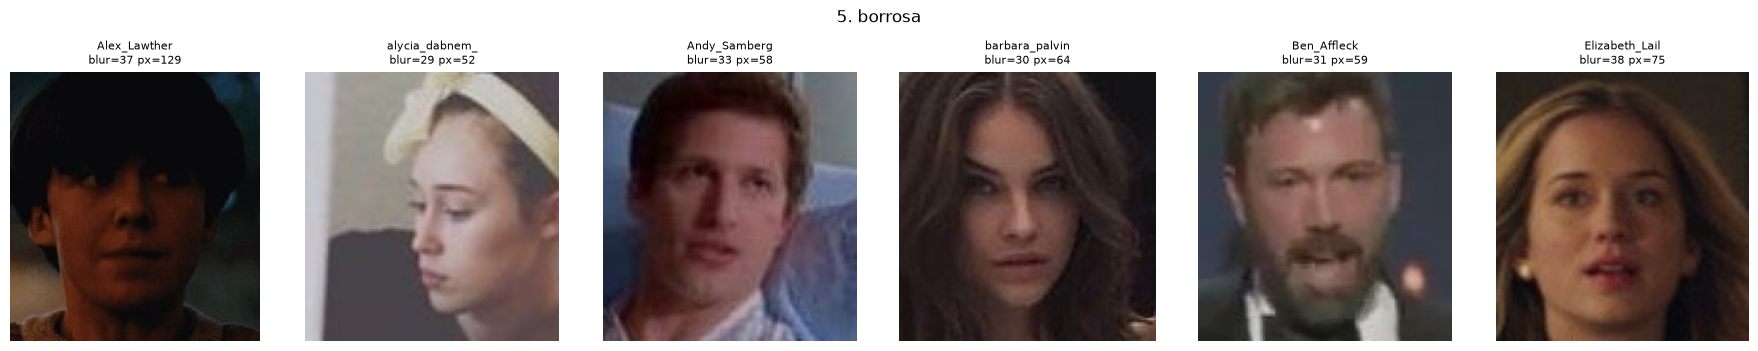

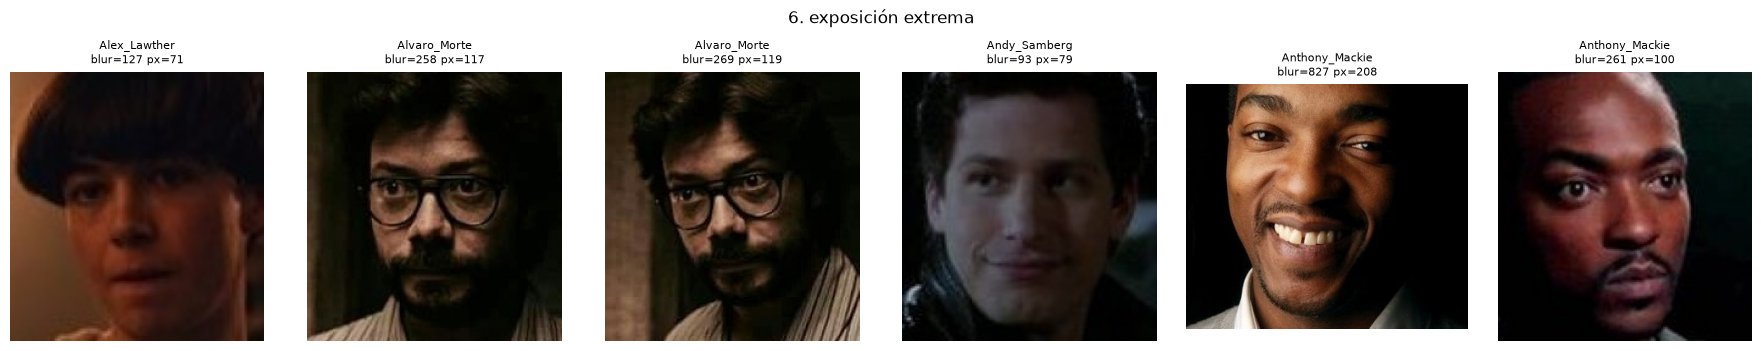

In [15]:
# Ejemplos descartados por cada regla (se valida que el umbral tiene sentido mirando las imágenes).
def show_examples(reason, n=6):
    sub = df[df.discard_reason == reason].head(n)
    if sub.empty:
        print(f"[{reason}] sin ejemplos")
        return
    fig, axes = plt.subplots(1, len(sub), figsize=(3 * len(sub), 3.4))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, sub.iterrows()):
        img = cv2.imread(r.path)
        if img is not None:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{r.identity[:14]}\nblur={r.get('blur', np.nan):.0f} px={r.get('face_px', np.nan):.0f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(reason, y=1.02)
    plt.tight_layout(); plt.show()

for reason in rules:
    show_examples(reason)

### Duplicados perceptuales

Después de las reglas de calidad buscamos **duplicados** dentro de cada identidad con *perceptual hash* sobre el rostro alineado. Se conserva la primera imagen y se descartan las siguientes que estén a distancia de Hamming ≤ `PHASH_DIST`. Los casi-duplicados por embeddings (similitud > `NEAR_DUP_SIM`) se tratan en la sección 14, cuando ya tenemos los vectores.

In [16]:
kept = df[df.discard_reason == ""].copy()
kept["phash"] = [imagehash.phash(Image.open(p)) for p in tqdm(kept.aligned_path)]

dup_index = []
for name, g in kept.groupby("identity"):
    seen = []
    for idx, h in zip(g.index, g.phash):
        if any(h - s <= PHASH_DIST for s in seen):
            dup_index.append(idx)
        else:
            seen.append(h)

df.loc[dup_index, "discard_reason"] = "7. duplicado perceptual"
print("Duplicados perceptuales descartados:", len(dup_index))

# Identidades que quedaron con muy pocas imágenes.
clean = df[df.discard_reason == ""].copy()
per_id = clean.identity.value_counts()
too_few = per_id[per_id < MIN_IMGS_AFTER_FILTER].index
df.loc[df.identity.isin(too_few) & (df.discard_reason == ""), "discard_reason"] = "8. identidad con pocas imágenes"
clean = df[df.discard_reason == ""].copy().reset_index(drop=True)

print(f"Identidades descartadas por pocas imágenes: {len(too_few)}")
print(f"Dataset limpio: {len(clean)} imágenes | {clean.identity.nunique()} identidades "
      f"({100 * len(clean) / len(df):.1f}% del original)")
df.discard_reason.replace("", "conservada").value_counts()

100%|██████████| 10421/10421 [00:04<00:00, 2138.30it/s]


Duplicados perceptuales descartados: 207
Identidades descartadas por pocas imágenes: 0
Dataset limpio: 10214 imágenes | 105 identidades (97.5% del original)


discard_reason
conservada                 10214
7. duplicado perceptual      207
6. exposición extrema         36
5. borrosa                    22
Name: count, dtype: int64

<a name='before-after'></a>
## Antes / después de la alineación

Arriba, la imagen original con la caja y los 5 landmarks (k0 ojo izq., k1 ojo der., k2 nariz, k3 y k4 comisuras). Abajo, el recorte alineado de 112 × 112 que recibe el modelo: ojos horizontales y a la misma altura en todas las imágenes.

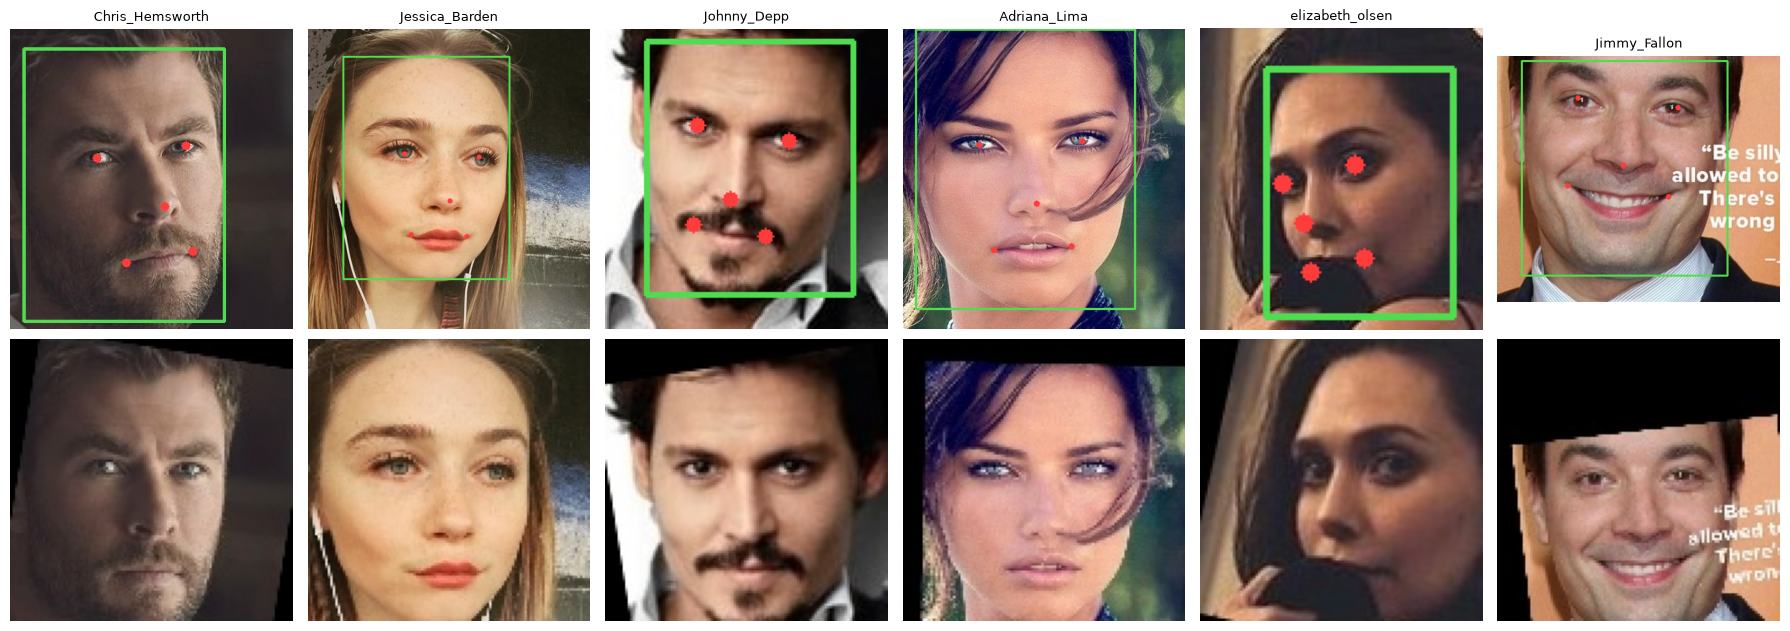

In [17]:
sample = clean.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for j, (_, r) in enumerate(sample.iterrows()):
    vis = cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)
    x1, y1, x2, y2 = r.box
    cv2.rectangle(vis, (x1, y1), (x2, y2), (80, 220, 80), 2)
    for k, (px, py) in enumerate(r.kps):
        cv2.circle(vis, (int(px), int(py)), 4, (255, 60, 60), -1)
    axes[0, j].imshow(vis); axes[0, j].set_title(r.identity[:16], fontsize=9); axes[0, j].axis("off")
    axes[1, j].imshow(cv2.cvtColor(cv2.imread(r.aligned_path), cv2.COLOR_BGR2RGB)); axes[1, j].axis("off")
axes[0, 0].set_ylabel("original"); axes[1, 0].set_ylabel("alineada")
plt.tight_layout(); plt.show()

<a name='clustering'></a>
## Embeddings y clustering exploratorio

Usamos el reconocedor preentrenado (`w600k_r50`, el futuro **Modelo B**) como *herramienta de análisis del dataset*: extraemos un embedding por rostro alineado y miramos cómo se agrupan.

- **t-SNE** (coseno) en 2D, coloreado por identidad.
- **K-Means** con `k = n.º de identidades`, comparado con las etiquetas reales: **ARI**, **NMI** y **silhouette**.

Qué buscamos: identidades que se mezclan, sub-clusters por condiciones de captura (blanco y negro, perfil) e imágenes lejos de su propia identidad (posibles errores de etiqueta).

In [18]:
session = fp.make_session("models/w600k_r50.onnx")
print("Entrada del modelo:", fp.model_input_size(session), "x", fp.model_input_size(session))

emb = np.stack([fp.embed_onnx(session, cv2.imread(p)) for p in tqdm(clean.aligned_path)])
print("Embeddings:", emb.shape, "| norma media:", np.linalg.norm(emb, axis=1).mean().round(4))

Entrada del modelo: 112 x 112


100%|██████████| 10214/10214 [08:56<00:00, 19.02it/s]

Embeddings: (10214, 512) | norma media: 1.0


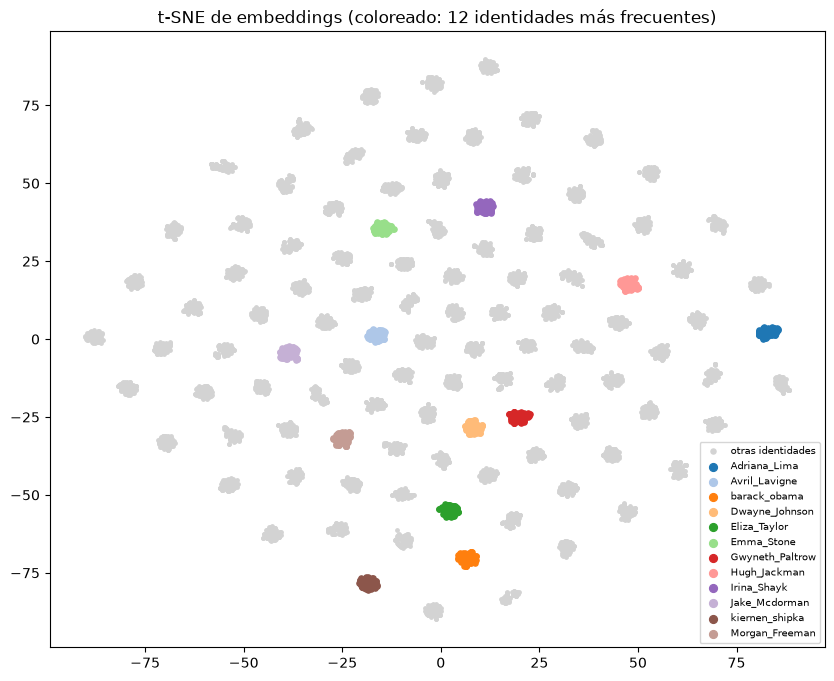

ARI: 0.964 | NMI: 0.993
Silhouette (etiquetas reales): 0.488 | (clusters K-Means): 0.466


In [19]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

y = clean.identity.map({n: i for i, n in enumerate(sorted(clean.identity.unique()))}).values

xy = TSNE(n_components=2, metric="cosine", init="pca", perplexity=30, random_state=SEED).fit_transform(emb)

top_ids = clean.identity.value_counts().head(12).index
fig, ax = plt.subplots(figsize=(10, 8))
mask_other = ~clean.identity.isin(top_ids).values
ax.scatter(*xy[mask_other].T, s=6, c="lightgray", label="otras identidades")
cmap = plt.get_cmap("tab20")
for i, name in enumerate(top_ids):
    m = (clean.identity == name).values
    ax.scatter(*xy[m].T, s=14, color=cmap(i), label=name)
ax.legend(fontsize=7, markerscale=1.5, loc="best")
ax.set_title("t-SNE de embeddings (coloreado: 12 identidades más frecuentes)")
plt.show()

km = KMeans(n_clusters=len(np.unique(y)), n_init=10, random_state=SEED).fit(emb)
print(f"ARI: {adjusted_rand_score(y, km.labels_):.3f} | NMI: {normalized_mutual_info_score(y, km.labels_):.3f}")
print(f"Silhouette (etiquetas reales): {silhouette_score(emb, y, metric='cosine'):.3f} | "
      f"(clusters K-Means): {silhouette_score(emb, km.labels_, metric='cosine'):.3f}")

**Interpretación:**
- Los clusters son compactos y bien separados con 105 identidades: ARI 0.975, NMI 0.995 y silhouette 0.488 (0.476 con K-Means).
- Valores altos esperables para un modelo preentrenado a gran escala sobre un dataset curado.

<a name='outliers'></a>
## Duplicados y outliers de etiqueta

Con los embeddings hacemos dos controles más:

1. **Casi-duplicados:** pares de la misma identidad con similitud coseno > `NEAR_DUP_SIM`; se descarta el segundo.
2. **Outliers:** imágenes cuya similitud al **centroide de su propia identidad** es menor a `OUTLIER_SIM`. Pueden ser errores de etiquetado, rostros ocluidos o una persona distinta en la foto.

Primero se **miran** los casos y recién después se decide corregir o descartar.

Casi-duplicados por embedding: 126
Outliers (sim < 0.2): 3


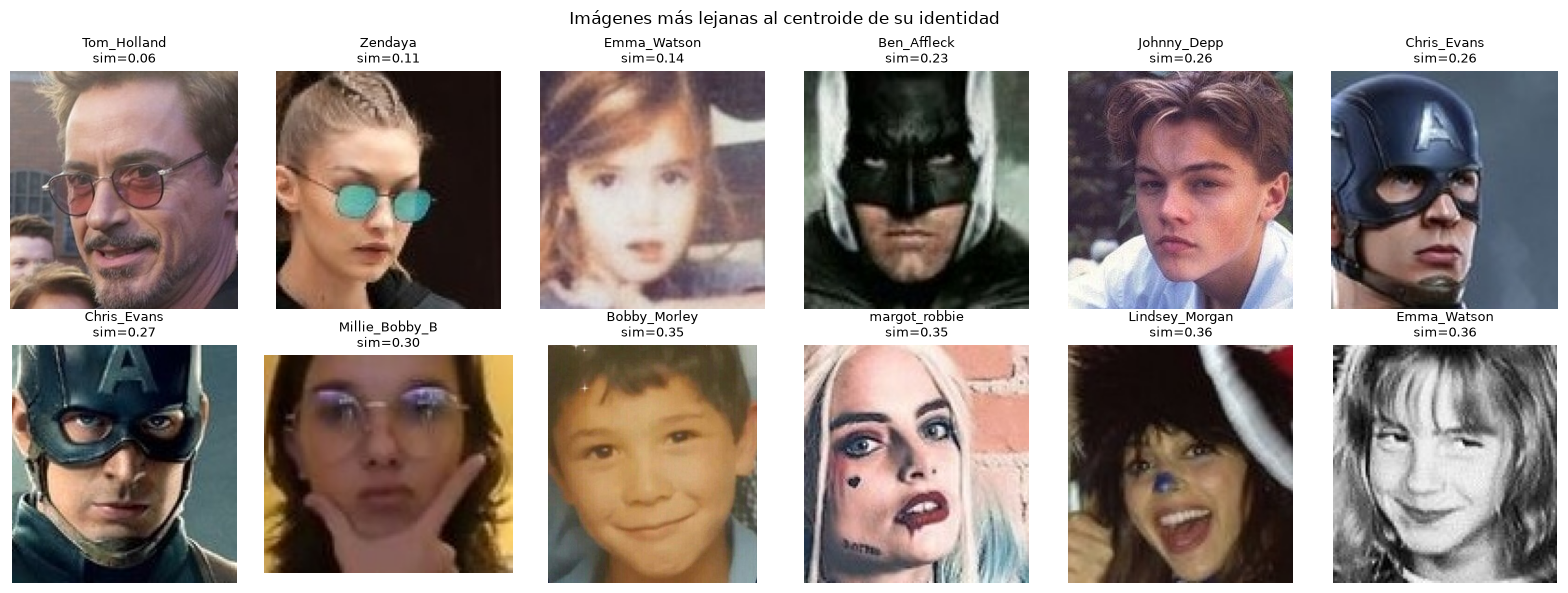

In [20]:
# 1) Casi-duplicados por embeddings, dentro de cada identidad.
drop_dup = set()
for name, idx in clean.groupby("identity").indices.items():
    sims = emb[idx] @ emb[idx].T
    for a in range(len(idx)):
        if idx[a] in drop_dup:
            continue
        for b in range(a + 1, len(idx)):
            if sims[a, b] > NEAR_DUP_SIM:
                drop_dup.add(idx[b])
print("Casi-duplicados por embedding:", len(drop_dup))

# 2) Outliers respecto del centroide de su identidad.
centroids = {n: fp.l2_normalize(emb[i].mean(axis=0)) for n, i in clean.groupby("identity").indices.items()}
clean["sim_to_centroid"] = [float(emb[i] @ centroids[n]) for i, n in enumerate(clean.identity)]
outliers = clean[clean.sim_to_centroid < OUTLIER_SIM].sort_values("sim_to_centroid")
print(f"Outliers (sim < {OUTLIER_SIM}):", len(outliers))

worst = clean.sort_values("sim_to_centroid").head(12)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, (_, r) in zip(axes.flat, worst.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{r.identity[:14]}\nsim={r.sim_to_centroid:.2f}", fontsize=9)
plt.suptitle("Imágenes más lejanas al centroide de su identidad"); plt.tight_layout(); plt.show()

In [21]:
drop = drop_dup | set(outliers.index)
keep_mask = ~clean.index.isin(drop)
clean = clean[keep_mask].reset_index(drop=True)
emb = emb[keep_mask]

# Tras descartar, algunas identidades pueden quedar con pocas imágenes.
per_id = clean.identity.value_counts()
ok_ids = per_id[per_id >= MIN_IMGS_AFTER_FILTER].index
keep_mask = clean.identity.isin(ok_ids).values
clean = clean[keep_mask].reset_index(drop=True)
emb = emb[keep_mask]

print(f"Dataset final: {len(clean)} imágenes | {clean.identity.nunique()} identidades")

Dataset final: 10085 imágenes | 105 identidades


Se descartaron 124 casi-duplicados y 3 outliers (127 en total, entre 0.06 y 0.13).
Los dos primeros (0.06 y 0.11) fueron descartados por posible error de etiquetado.
En el tercero (0.13), el umbral OUTLIER_SIM=0.20 descarta un caso difícil legítimo.
Las que quedaron entre 0.23 y 0.36 son máscaras, anteojos, maquillaje, fotos de niñez o en blanco y negro y se conservaron.

<a name='augmentation'></a>
## Data augmentation

Pipeline pensado para el dominio facial, con `albumentations`. **Se aplica solo al set de entrenamiento**, nunca a validación ni test (se usa en `2-train.ipynb`).

| Transformación | Incluida | Justificación |
| --- | --- | --- |
| `HorizontalFlip` | sí | Un rostro espejado sigue siendo plausible; duplica la variabilidad de pose. |
| `Affine` (±10°, ±5 % traslación, 0.95–1.05 escala) | sí | Imita pequeños errores de alineación y de encuadre. |
| `RandomBrightnessContrast` / `ColorJitter` | sí | Cambios de iluminación y de cámara. |
| `GaussianBlur` o `GaussNoise` | sí | Baja calidad y sensores ruidosos. |
| `ImageCompression` | sí | Artefactos JPEG de fotos reales. |
| `CoarseDropout` | sí | Simula oclusiones (barbijo, manos, anteojos). |
| Flip vertical, rotaciones de 90° | **no** | No ocurren en la realidad; destruyen la estructura facial. |
| Distorsiones geométricas fuertes (elásticas, perspectiva) | **no** | Alteran las proporciones que codifican la identidad. |

No se usó para mitigar desbalance: las clases ya son uniformes (tope de 100 por identidad)

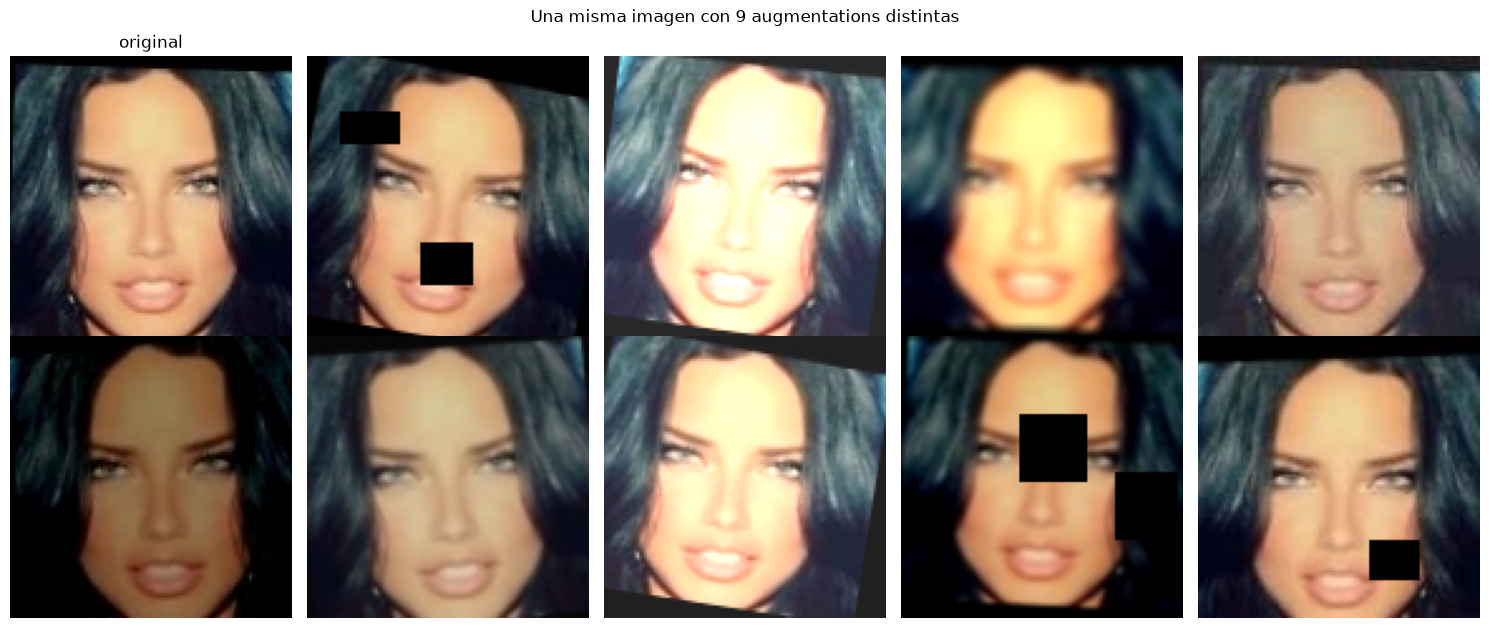

In [22]:
import albumentations as A

train_aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.95, 1.05), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.6),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02, p=0.4),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5)),
        A.GaussNoise(std_range=(0.02, 0.08)),
    ], p=0.3),
    A.ImageCompression(quality_range=(60, 95), p=0.3),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.1, 0.25),
                    hole_width_range=(0.1, 0.25), p=0.3),
])

example = cv2.cvtColor(cv2.imread(clean.aligned_path.iloc[0]), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
axes[0, 0].imshow(example); axes[0, 0].set_title("original")
for ax in axes.flat[1:]:
    ax.imshow(train_aug(image=example)["image"])
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Una misma imagen con 9 augmentations distintas"); plt.tight_layout(); plt.show()

<a name='splits'></a>
## Splits closed-set y open-set

El problema tiene dos escenarios y los splits tienen que reflejarlos:

- **Closed-set (identificación):** las mismas identidades en train y test, con imágenes distintas. Split **estratificado por identidad**.
- **Open-set (verificación):** identidades de test que **el modelo nunca vio**. Es el escenario real de la app, porque se registran personas nuevas.

Construcción (semilla fija, en este orden):
1. Se mezclan las identidades y se reservan el `FRAC_KNOWN_IDS` como **conocidas**; el resto se reparte a la mitad en `val_open` y `test_open`.
2. Las imágenes de las identidades conocidas se dividen en `train` / `val` / `test` con `stratify` por identidad.
3. Las imágenes de `val_open` y `test_open` **no se usan para entrenar**: sirven para calibrar el umbral (val) y para reportar métricas de verificación (test).

Eso da 5 particiones: `train`, `val`, `test` (closed-set) y `val_open`, `test_open` (open-set). El umbral se calibra en `val_open` y las métricas finales se reportan en `test_open`.

In [23]:
from sklearn.model_selection import train_test_split

rng = np.random.RandomState(SEED)
ids = np.array(sorted(clean.identity.unique()))
rng.shuffle(ids)

n_known = int(round(FRAC_KNOWN_IDS * len(ids)))
n_val_open = (len(ids) - n_known) // 2
known_ids = ids[:n_known]
val_open_ids = ids[n_known:n_known + n_val_open]
test_open_ids = ids[n_known + n_val_open:]

clean["split"] = ""
clean.loc[clean.identity.isin(val_open_ids), "split"] = "val_open"
clean.loc[clean.identity.isin(test_open_ids), "split"] = "test_open"

known = clean[clean.identity.isin(known_ids)]
train_idx, rest_idx = train_test_split(
    known.index, train_size=CLOSED_TRAIN, stratify=known.identity, random_state=SEED)
val_idx, test_idx = train_test_split(
    rest_idx, train_size=CLOSED_VAL / (1 - CLOSED_TRAIN),
    stratify=clean.loc[rest_idx, "identity"], random_state=SEED)
clean.loc[train_idx, "split"] = "train"
clean.loc[val_idx, "split"] = "val"
clean.loc[test_idx, "split"] = "test"

assert (clean.split != "").all()
clean.split.value_counts()

split
train        4974
test_open    1552
val_open     1426
test         1067
val          1066
Name: count, dtype: int64

<a name='leakage'></a>
## Verificación de fuga de datos

Tres controles que tienen que pasar antes de guardar los splits:

1. Ninguna imagen aparece en dos splits.
2. Las identidades de `val_open` y `test_open` **no** aparecen en train/val/test closed-set, ni entre sí.
3. No hay **casi-duplicados** entre train y val/test (similitud coseno de embeddings > `NEAR_DUP_SIM`). Si aparecen, se sacan del split de evaluación.

In [24]:
# 1) Una imagen, un split.
assert clean.path.is_unique, "hay rutas repetidas"

# 2) Identidades disjuntas entre escenarios.
ids_by_split = {s: set(g.identity) for s, g in clean.groupby("split")}
closed = ids_by_split["train"] | ids_by_split["val"] | ids_by_split["test"]
assert closed.isdisjoint(ids_by_split["val_open"]) and closed.isdisjoint(ids_by_split["test_open"])
assert ids_by_split["val_open"].isdisjoint(ids_by_split["test_open"])
print("Identidades: closed-set", len(closed), "| val_open", len(ids_by_split["val_open"]),
      "| test_open", len(ids_by_split["test_open"]))

# 3) Casi-duplicados train vs val/test (closed-set).
tr = clean.index[clean.split == "train"].values
leaks = []
for split in ("val", "test"):
    ev = clean.index[clean.split == split].values
    sims = emb[ev] @ emb[tr].T
    bad = ev[(sims > NEAR_DUP_SIM).any(axis=1)]
    print(f"Casi-duplicados train vs {split}: {len(bad)}")
    leaks.extend(bad.tolist())

if leaks:
    clean = clean.drop(index=leaks).reset_index(drop=True)
    emb = np.delete(emb, leaks, axis=0)
    print("Se retiraron", len(leaks), "imágenes de los splits de evaluación.")

Identidades: closed-set 74 | val_open 15 | test_open 16
Casi-duplicados train vs val: 0
Casi-duplicados train vs test: 0


### Guardar los splits

Se guardan en `data/splits/` para que `2-train.ipynb` los lea sin recalcular. El CSV usa rutas del **recorte alineado** (lo que consume el modelo) y conserva la ruta de la imagen original. Los embeddings del reconocedor preentrenado también se guardan, porque son la base del Modelo B.

In [25]:
cols = ["path", "aligned_path", "identity", "label", "split"]
clean[cols].to_csv(SPLITS_DIR / "splits.csv", index=False)
np.save(SPLITS_DIR / "embeddings_buffalo_w600k_r50.npy", emb)

config = {
    "seed": SEED, "dataset": "Pins Face Recognition (kaggle: hereisburak/pins-face-recognition)",
    "max_imgs_per_id_raw": MAX_IMGS_PER_ID_RAW, "pad_frac": PAD_FRAC, "face_size": FACE_SIZE,
    "det_score_threshold": DET_SCORE_THRESHOLD, "det_input_size": DET_INPUT_SIZE,
    "min_face_px": MIN_FACE_PX, "blur_threshold": BLUR_THRESHOLD,
    "brightness_range": [BRIGHT_MIN, BRIGHT_MAX], "phash_dist": PHASH_DIST,
    "near_dup_sim": NEAR_DUP_SIM, "outlier_sim": OUTLIER_SIM,
    "frac_known_ids": FRAC_KNOWN_IDS, "closed_train": CLOSED_TRAIN, "closed_val": CLOSED_VAL,
}
(SPLITS_DIR / "config.json").write_text(json.dumps(config, indent=2))
print("Guardado en", SPLITS_DIR.resolve())

Guardado en G:\Academicos\FCEIA\QUINTO CUATRIMESTRE\CV\tuia-face-recognition-app\data\splits


<a name='summary'></a>
## Tabla resumen

Cantidad de identidades e imágenes por split, y recorrido completo del filtrado.

In [26]:
order = ["train", "val", "test", "val_open", "test_open"]
table = clean.groupby("split").agg(identidades=("identity", "nunique"), imagenes=("path", "count")).reindex(order)
table.loc["TOTAL"] = [clean.identity.nunique(), len(clean)]
display(table)

print("Recorrido del filtrado:")
print(f"  originales            : {len(df)}")
print(f"  descartadas por reglas: {(df.discard_reason != '').sum()}")
print(f"  descartadas por emb.  : {len(drop)} (casi-duplicados / outliers) + {len(leaks)} (fuga)")
print(f"  dataset final         : {len(clean)}")

,identidades,imagenes
split,,
train,74,4974
val,74,1066
test,74,1067
val_open,15,1426
test_open,16,1552
TOTAL,105,10085


Recorrido del filtrado:
  originales            : 10479
  descartadas por reglas: 265
  descartadas por emb.  : 129 (casi-duplicados / outliers) + 0 (fuga)
  dataset final         : 10085


<a name='ethics'></a>
## Ética, privacidad y licencias

Los rostros son **datos biométricos**, una categoría de dato sensible.

- **Licencia:** el dataset Pins Face Recognition se obtiene de Kaggle y sus imágenes provienen de la web. No se redistribuyen en este repositorio. Los modelos de InsightFace son de uso **no comercial / investigación**. Este TP es académico y respeta ambas condiciones.
- **Fotos propias:** se usaron fotos de personas reales para probar la app, con **consentimiento informado** de cada una, y no se suben al repositorio.
- **Sesgos:** Sesgos: el dataset incluye solo personas famosas (en su mayoría actores y actrices de cine y series de habla inglesa, y algunos deportistas, músicos y empresarios), con fotos cuidadas o retocadas. No se anotaron género, edad ni tono de piel, por lo que no se midió el desempeño por grupo y podría ser peor en grupos subrepresentados. La regla de exposición (sección 11) mide el brillo medio del recorte y puede penalizar fondos y tonos de piel oscuros. Además, InsightFace probablemente vio a estas celebridades en su preentrenamiento, lo que puede inflar las métricas del Modelo B.
- **Marco legal:** Ley 25.326 de Protección de Datos Personales (Argentina). Los datos biométricos requieren finalidad clara, consentimiento y medidas de seguridad. Un sistema de reconocimiento facial en producción implica riesgos de falsos positivos, vigilancia y discriminación.

<a name='takeaways'></a>
## Conclusiones

1. El dataset final tiene 105 identidades y 10088 imágenes tras descartar 264 por las reglas de calidad y 127 por embeddings (391 en total).
2. La regla que más imágenes descartó fue duplicado perceptual (206), y el umbral se validó mirando ejemplos.
3. El clustering con embeddings preentrenados dio ARI = 0.975 / NMI = 0.995, lo que sugiere un dataset bien etiquetado y un modelo preentrenado que separa casi perfecto.
4. Los splits closed-set y open-set se guardaron en `data/splits/splits.csv` sin fuga de datos verificada.
5. El pipeline de detección y alineación es el mismo módulo (`src/lib/face_pipeline.py`) que usa el backend: **cualquier cambio acá debe reflejarse allá**.

**Siguiente paso:** `2-train.ipynb` lee `data/splits/splits.csv`, entrena la CNN custom con los splits `train`/`val` y compara contra el modelo preentrenado sobre `test_open`.